In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [122]:
# Problem 2c
A = np.diag([2, 1])
b = np.array([2, 1])
f = lambda x: np.linalg.norm(A @ x - b) ** 2 / 2
grad = lambda x: A.T @ (A @ x - b)
mu = 1 / 8
s = 1

def project(x):
    xp = [max(0, v) for v in x]
    no_pos = [v if v else float('-inf') for v in xp]
    S = np.argpartition(no_pos, -s)[-s:]
    return np.array([xp[i] if i in S else 0 for i in range(len(xp))])

def train(x, T=100):
    for _ in range(T):
        x = project(x - mu * grad(x))
    return x

def plot_convergence():
    globe, local = [], []
    for i in np.linspace(-5, 5, 100):
        for j in np.linspace(-5, 5, 100):
            x = np.array([i, j])
            if np.linalg.norm(train(x) - np.array([1, 0])) < 1e-2: 
                globe.append(x)
            else: 
                local.append(x)

    plt.scatter([i[0] for i in globe], [i[1] for i in globe], color='green')
    plt.scatter([i[0] for i in local], [i[1] for i in local], color='red')
    plt.show()

# plot_convergence()

In [127]:
# Problem 3
data = pd.read_csv("data/HW7Q3.csv", header=None)
A = data.values[:, :-1]
b = data.values[:, -1]

f = lambda x: np.linalg.norm(A @ x - b) ** 2 / 2
grad = lambda x: A.T @ (A @ x - b)
mu = 1e-2

def project(x):
    xabs = [abs(v) for v in x]
    S = np.argpartition(xabs, -2)[-2:]
    return np.array([x[i] if i in S else 0 for i in range(len(x))])

def train(x, T=10_000):
    losses = np.array([f(x)])
    for _ in range(T):
        x = project(x - mu * grad(x))
        losses = np.append(losses, f(x))

    plt.plot(losses)
    plt.title("Loss")
    plt.show()
    return {i: v for i, v in enumerate(x) if v}

# train(np.zeros(50), T=100)

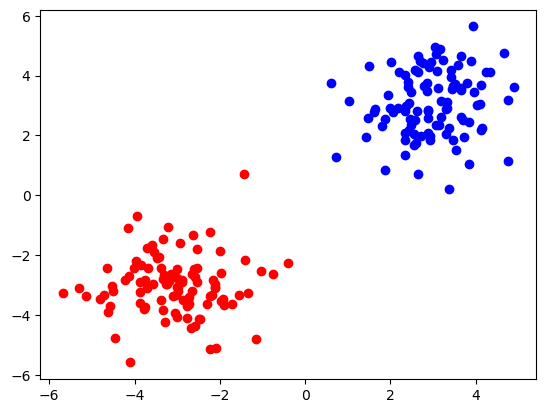

In [132]:
# Problem 4a
data = pd.read_csv("data/HW7Q4.csv", header=None)
plt.scatter(data.values[:100, 0], data.values[:100, 1], color='blue')
plt.scatter(data.values[100:, 0], data.values[100:, 1], color='red')
plt.show()

In [136]:
# Problem 4b
X = data.values[:, :-1]
Y = data.values[:, -1]

L_one = lambda w, x, y: max(0, 1 - y * np.dot(w, x))
L = lambda w: w @ w / 2 + sum(L_one(w, x, y) for x, y in zip(X, Y))

grad_one = lambda w, x, y: -y * x * (1 - y * np.dot(w, x) > 0)
grad = lambda w: w + sum(grad_one(w, x, y) for x, y in zip(X, Y))

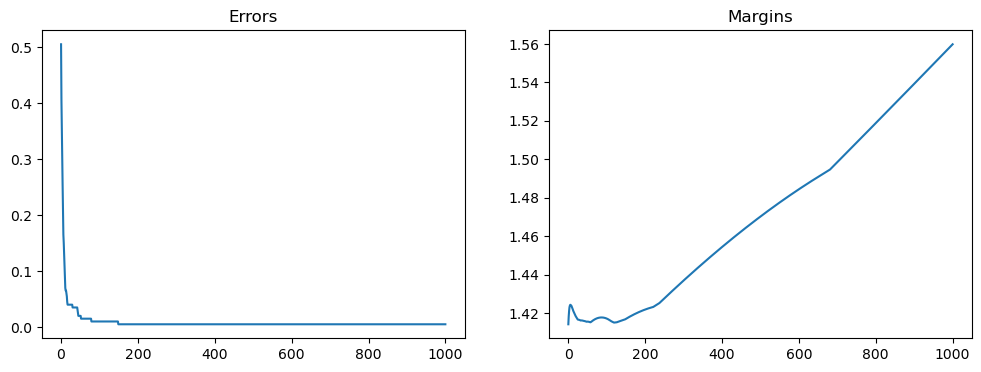

In [187]:
# Problem 4c
mu = 1e-4
w = np.array([-1, 1])

def class_error(w):
    error = lambda x, y: (1 - y * np.sign(np.dot(w, x))) / 2
    return sum([error(x, y) for x, y in zip(X, Y)]) / len(X)

def train(w, T=1_000):
    errors = np.array([class_error(w)])
    margins = np.array([2 / np.linalg.norm(w)])
    for _ in range(T):
        w = w - mu * grad(w)
        errors = np.append(errors, class_error(w))
        margins = np.append(margins, 2 / np.linalg.norm(w))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(errors)
    ax[0].set_title("Errors")
    ax[1].plot(margins)
    ax[1].set_title("Margins")
    plt.show()
    return w

w = train(w)

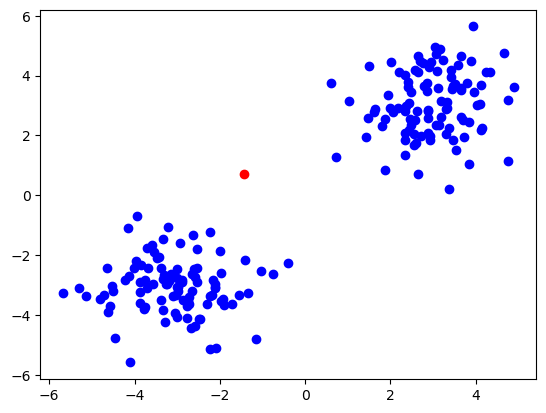

In [191]:
error = lambda x, y: (1 - y * np.sign(np.dot(w, x))) / 2
for x, y in zip(X, Y):
    if error(x, y): plt.scatter(x[0], x[1], color='red')
    else: plt.scatter(x[0], x[1], color='blue')
plt.show()

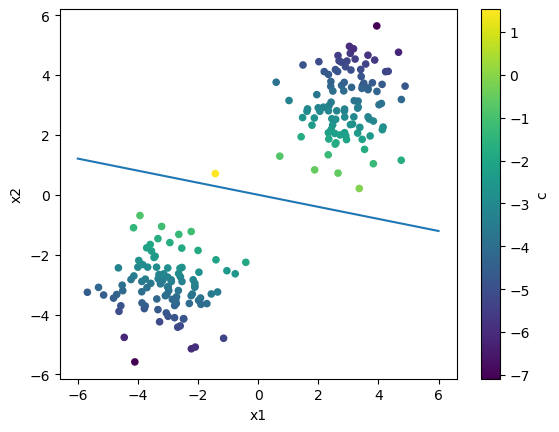

In [200]:
data.rename(columns={0: 'x1', 1: 'x2', 2: 'y'}, inplace=True)
color = lambda row: 1 - row['y'] * np.dot(w, [row['x1'], row['x2']])
colored = data.assign(c=data.apply(color, axis=1))
colored.plot(kind='scatter', x='x1', y='x2', c='c')

x = np.array([-6, 6])
y = -w[0] / w[1] * x
plt.plot(x, y)
plt.show()